In [54]:
from numba import njit
import numpy as np
import matplotlib.pyplot as plt

# Algorithm
Consider the differential equation
$$
    \dot{\bold{y}} = \bold{F} (\bold{y}, t)
$$

The implicit-midpoint algorithm has
$$
\bold{Y}_1 = \bold{y}^n + \frac{h_{n+1}}{2} \bold{F} \left(\bold{Y}_1, t_n + \frac{h_{n+1}}{2}\right)
$$

with the next value as
$$
    \bold{y}^{n+1} = 2 \bold{Y}_1 - \bold{y}^n 
$$

## Implicit Solver
To solve the implicit equation, we consider the residue function
$$\bold{R(\bold Y)} = \bold{Y} - \bold{y}^n - \frac{h_{n+1}}{2} \bold{F} \left(\bold{Y}, t_n + \frac{h_{n+1}}{2}\right)$$

This setup is solved using the recurrence relation
$$\frac{\partial \bold{R}}{\partial \bold Y} (\bold Y^{n+1} - \bold Y^n) = - \bold R (\bold Y^n)$$

# Physical System
Hamiltonian for a simple pendulum:

$$\mathcal{H} = \frac{p^2}{2m\ell^2} - mg\ell \cos q$$

The corresponding derivatives are given by

$$
\begin{align*}
    \mathcal{H}_p &= \frac{p} {m \ell^2} \\
    \mathcal{H}_q &= mg\ell \sin q
\end{align*}
$$

## Mathematical Details

The system is given by
$$\bold X = \begin{bmatrix} p \\ q \end{bmatrix}$$

The rate change is given by
$$\dot{\bold X} = \bold F (\bold X, t) = \begin{bmatrix} - \mathcal{H}_p \\ \mathcal{H}_q \end{bmatrix}$$

The residue function therefore becomes:
$$\bold R (\bold Y) = \bold Y - \bold{y}^n - \frac{h}{2} \begin{bmatrix} - \mathcal{H}_p  (\bold Y, t) \\ \mathcal{H}_q  (\bold Y, t) \end{bmatrix}$$

The Hessian matrix is therefore
$$
\begin{align*}
\frac{\partial \bold{R}}{\partial \bold Y} &= 
    \begin{bmatrix} 
        \frac{\partial R_1}{\partial Y_1} & \frac{\partial R_1}{\partial Y_2} \\
        \frac{\partial R_2}{\partial Y_1} & \frac{\partial R_2}{\partial Y_2} 
    \end{bmatrix} \\

&= \begin{bmatrix} 
        1 + \frac{h}{2} \mathcal{H}_{pp} & \frac{h}{2} \mathcal{H}_{pq} \\ 
        - \frac{h}{2} \mathcal{H}_{pq} & 1 - \frac{h}{2} \mathcal{H}_{qq}
    \end{bmatrix} \\

& = \begin{bmatrix}
        1 + \frac{h}{2} \frac{1}{m\ell^2} & 0 \\
        0 & 1 - \frac{h}{2} mg\ell \cos q
    \end{bmatrix}
\end{align*}
$$


In [51]:
# equations of motion for a simple pendulum

m = 1
l = 1
g = 9.81

# derivatives of hamiltonian
@njit
def H_p(p, q, t):
    return p / (m * l ** 2)

@njit
def H_q(p, q, t):
    return m * g * l * np.sin(q)

@njit
def residue(Y, y0, t, dt):
    return Y - y0 - (dt / 2) * np.array([-H_p(Y[0], Y[1], t), H_q(Y[0], Y[1], t)])

@njit
def residue_hessian(Y, t, dt):
    return np.array([
        [1 + 0.5 * dt / (m * l * l), 0], 
        [0, 1 - 0.5 * m * g * l * np.cos(Y[1])]
    ])

In [69]:
@njit
def solve_implicit(y0, res, hess, t, dt, max_iter=100):
    Y = y0
    for i in range(max_iter):
        curr_res = res(Y, y0, t, dt)

        if np.allclose(curr_res, 0):
            break

        curr_hess = hess(Y, t, dt)

        delY = np.linalg.solve(curr_hess, - curr_res)

        Y = Y + delY        

    return Y

@njit
def implicit_midpoint(p0, q0, t0, dt, N):

    p = np.empty(N+1)
    q = np.empty(N+1)
    t = t0 + dt * np.arange(N+1)


    p[0] = p0
    q[0] = q0

    for i in range(N):
        y0 = np.array([p[i], q[i]])

        Y = solve_implicit(y0, residue, residue_hessian, t, dt)

        y1 = 2 * Y - y0

        p[i+1] = y1[0]
        q[i+1] = y1[1]

    return p, q, t

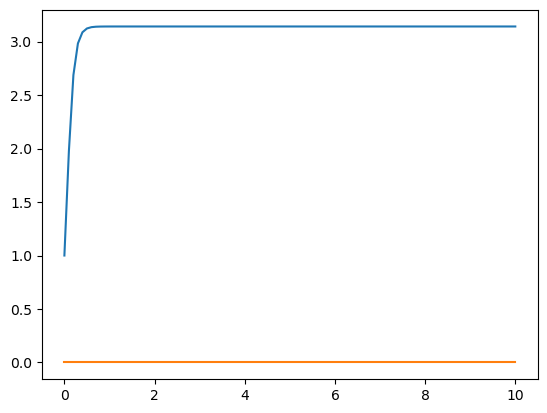

In [70]:
p,q,t = implicit_midpoint(0, 1, 0, 0.1, 100)

plt.plot(t, q)
plt.plot(t, p)